In [19]:
import pandas as pd
import numpy as np
df=pd.read_csv("auto-mpg.csv")
df.columns=[
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin"]
print(df.head(5))

print(df["mpg"].mean())
print(df["horsepower"].dtype)
df["horsepower"].str.replace("?", "")
df["horsepower"] = pd.to_numeric(
    df["horsepower"].replace("?", np.nan),
    errors="coerce"
)

df["horsepower"]=df["horsepower"].fillna(df["horsepower"].mean())
print(df.isna().sum())
print(df["horsepower"].mean())
print(df["mpg"].min())
print(df["mpg"].max())

    mpg  cylinders  displacement horsepower  weight  acceleration  model_year  \
0  15.0          8         350.0        165    3693          11.5          70   
1  18.0          8         318.0        150    3436          11.0          70   
2  16.0          8         304.0        150    3433          12.0          70   
3  17.0          8         302.0        140    3449          10.5          70   
4  15.0          8         429.0        198    4341          10.0          70   

   origin  
0       1  
1       1  
2       1  
3       1  
4       1  
23.528463476070527
str
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64
104.40409207161125
9.0
46.6


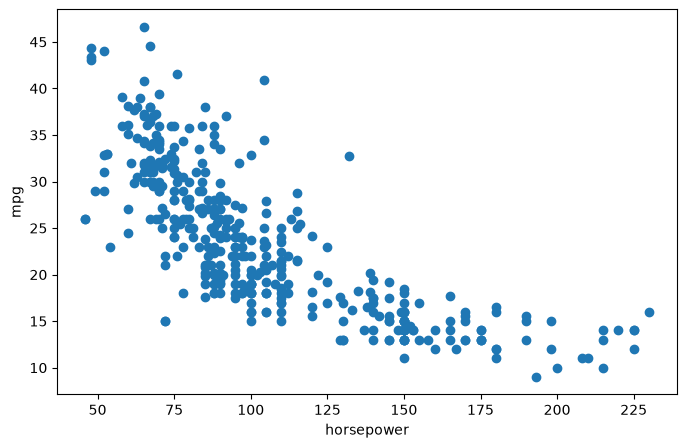

In [21]:
import matplotlib.pyplot as mp
mp.figure(figsize=(8,5))
mp.scatter( df["horsepower"],
    df["mpg"]
)
mp.xlabel("horsepower")
mp.ylabel("mpg")
mp.show()

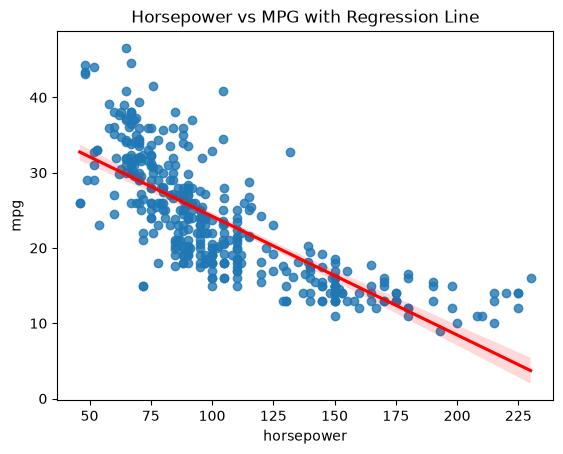

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(
    data=df,
    x="horsepower",
    y="mpg",
    line_kws={"color": "red"}
)

plt.title("Horsepower vs MPG with Regression Line")
plt.show()

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np
X= df[["horsepower"]]
y=df["mpg"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
model = LinearRegression()
model.fit(X_train, y_train)
print("Slope:", model.coef_)
print("Intercept:", model.intercept_)
y_pred = model.predict(X_test)

print("Predicted MPG:")
print(y_pred[:10])

print("Actual MPG:")
print(y_test[:10].values)


mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

(317, 1)
(80, 1)
(317,)
(80,)
Slope: [-0.16325268]
Intercept: 40.61555840877206
Predicted MPG:
[16.94392043 29.51437646 27.06558632 27.55534435 19.39271057 28.37160773
 17.76018381 16.12765705 28.86136576 27.55534435]
Actual MPG:
[15.  29.5 33.5 25.  13.  33.7 13.  16.  15.  28.1]
MAE: 3.716963399938723
MSE: 23.64724231330409
RMSE: 4.8628430278288945
R2 Score: 0.5412213078531931


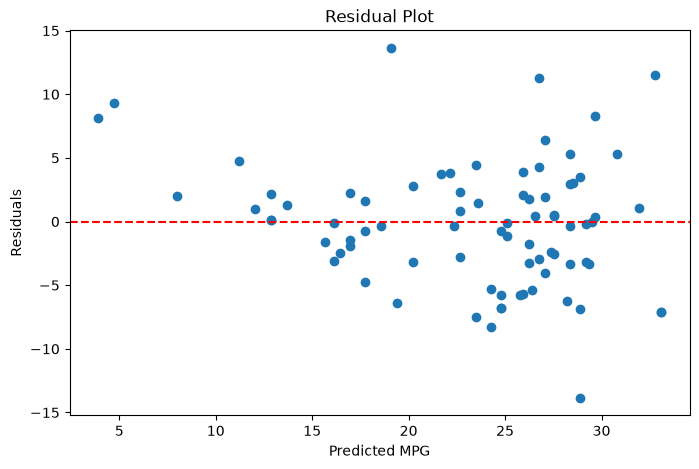

In [32]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted MPG")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X1 = df[["horsepower", "weight"]]
y1 = df["mpg"]
from sklearn.model_selection import train_test_split

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

model2 = LinearRegression()

model2.fit(X1_train, y1_train)
print("Coefficients:", model2.coef_)
print("Intercept:", model2.intercept_)
y_pred2 = model2.predict(X1_test)
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

print("MAE:", mean_absolute_error(y1_test, y1_pred2))
print("MSE:", mean_squared_error(y1_test, y1_pred2))
print("RMSE:", np.sqrt(mean_squared_error(y1_test, y_pred2)))
print("R2:", r2_score(y_test, y_pred2))

Coefficients: [-0.04240551 -0.00627193]
Intercept: 46.60763172271855
